# BAB IV — Klasifikasi Entri Software GLPI (CRISP-DM)

**Tujuan:** mengklasifikasikan entri Software Inventory hasil GLPI Agent menjadi `INCLUDE` (aplikasi utama) dan `EXCLUDE_CANDIDATE` (kandidat entri non-utama) untuk membantu *review* tim IT atas pengelolaan Software Dictionary. **Prediksi bukan perintah menghapus/mengabaikan import secara otomatis.**

**Data utama berlabel:** `Software_GLPI_2000.xlsx` (atau `.csv`), dengan kolom asli `software_id`, `software_name`, `manufacturer`, `software_category`, `entity_id`, `label`.

**Data historis untuk konteks (opsional):** `SoftwareDataset.csv` (12.318 entri mentah). Tidak digunakan sebagai data berlabel dalam pelatihan.

**Penting:** file yang digunakan sebagai dataset berlabel harus benar-benar salinan hasil review Pak Widi. Jika file yang dimiliki masih `Label_Awal`, jangan laporkan angka evaluasinya sebagai kinerja terhadap label IT.

**Alur:** Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

## 4.1 Business Understanding

**Masalah operasional:** Software Inventory GLPI mencatat aplikasi utama bersama entri pelengkap (pembaruan, language pack, driver, runtime, komponen, dan nama yang sulit diidentifikasi). Untuk keperluan daftar aplikasi utama, tim IT perlu membedakan entri yang relevan dari entri pendukung. GLPI sudah mempunyai Software Dictionary yang mendukung kriteria dan aturan; penelitian ini menguji apakah rekomendasi klasifikasi berbasis ML dapat **membantu review**, bukan mengganti kapabilitas GLPI.

**Pertanyaan penelitian:** (1) Bagaimana menerapkan klasifikasi teks pada nama entri software GLPI dengan kriteria label yang disepakati IT? (2) Bagaimana perbandingan TF-IDF + Logistic Regression dan TF-IDF + Linear SVM pada sampel yang sudah divalidasi IT?

**Ruang lingkup:** hanya rekomendasi klasifikasi entri, **bukan** deteksi software bajakan, validasi keamanan, penghapusan otomatis, atau pembuktian peningkatan performa database.

**Definisi operasional label perlu ditetapkan bersama IT:** `INCLUDE` = entri aplikasi utama yang ingin dipertahankan untuk daftar utama; `EXCLUDE_CANDIDATE` = entri yang patut ditinjau karena kemungkinan hanya update, patch, driver, komponen pendukung, runtime, dan sejenisnya. `EXCLUDE_CANDIDATE` tidak berarti tidak penting atau harus dihapus dari data inventaris.

#### KODE 01 — Konfigurasi proyek dan nama file

In [1]:
from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / 'output_bab4'
FIG_DIR = OUT_DIR / 'figures'
MODEL_DIR = OUT_DIR / 'models'
for folder in (OUT_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Final, reviewed file only. Do not silently fall back to a proposed-label file.
INPUT_BASENAME = 'Software_GLPI_2000'
RAW_FILENAME = 'SoftwareDataset.csv'  # optional
VALID_LABELS = {'INCLUDE', 'EXCLUDE_CANDIDATE'}
print('Folder kerja:', BASE_DIR)
print('Folder hasil:', OUT_DIR)

Folder kerja: c:\Users\magang.tiga\Documents\CODE_GLPI
Folder hasil: c:\Users\magang.tiga\Documents\CODE_GLPI\output_bab4


#### KODE 02 — Memuat dataset hasil review Pak Widi

In [3]:
def load_reviewed_input(base_name):
    options = [BASE_DIR / f'{base_name}.xlsx', BASE_DIR / f'{base_name}.csv']
    candidate = next((p for p in options if p.exists()), None)
    if candidate is None:
        raise FileNotFoundError(
            f'Letakkan FILE HASIL REVIEW sebagai {base_name}.xlsx atau {base_name}.csv '
            f'di folder {BASE_DIR}. File Label_Awal tidak dipakai otomatis.'
        )
    if candidate.suffix.lower() == '.xlsx':
        data = pd.read_excel(candidate, dtype={'software_id': str, 'software_name': str})
    else:
        for enc in ('utf-8-sig', 'utf-8', 'cp1252'):
            try:
                data = pd.read_csv(candidate, encoding=enc, dtype={'software_id': str, 'software_name': str})
                break
            except UnicodeDecodeError:
                continue
        else:
            raise ValueError('Encoding CSV tidak dikenali.')
    return candidate, data

source_path, original_labeled = load_reviewed_input(INPUT_BASENAME)
required = {'software_id', 'software_name', 'manufacturer', 'software_category', 'entity_id', 'label'}
missing_cols = required - set(original_labeled.columns)
if missing_cols:
    raise ValueError(f'Kolom wajib tidak tersedia: {missing_cols}')
print('File:', source_path.name)
print('Ukuran data:', original_labeled.shape)
display(original_labeled.head(10))

File: Software_GLPI_2000.xlsx
Ukuran data: (2000, 6)


,software_id,software_name,manufacturer,software_category,entity_id,label
0,"18,431",AutoCAD LT 2020 Language Pack - English,AUTODESK,system_component,0,EXCLUDE_CANDIDATE
1,"3,511","Adobe Acrobat 7.0 Professional - English, Fran...",Adobe Systems,NaN,0,INCLUDE
2,"8,429",SIMATIC WinCC/WebNavigator Plug-In Builder,Siemens AG,NaN,0,EXCLUDE_CANDIDATE
3,"36,284",Microsoft Project Professional 2024 - id-id,Microsoft Corporation,application,0,INCLUDE
4,"26,823",Microsoft Office Home and Business 2024 - id-id,Microsoft Corporation,application,0,INCLUDE
5,"38,328",ACR_18_7_32,Adobe Inc.,application,0,INCLUDE
6,"26,849",Autodesk AutoCAD Civil 3D 2018 - English,NaN,application,0,INCLUDE
7,"29,088",RealVNC Server 7.10.0,RealVNC,application,0,INCLUDE
8,"33,733",Microsoft Save as PDF Add-in for 2007 Microsof...,Microsoft Corporation,application,0,EXCLUDE_CANDIDATE
9,"23,131",AMD I2C Driver,"Advanced Micro Devices, Inc.",system_component,0,EXCLUDE_CANDIDATE


#### KODE 03 — Memuat dataset mentah GLPI (untuk konteks)

In [4]:
raw_path = BASE_DIR / RAW_FILENAME
if raw_path.exists():
    raw_data = pd.read_csv(raw_path, encoding='utf-8-sig', low_memory=False, dtype={'software_id': str})
    print('Dataset mentah tersedia:', raw_data.shape)
    display(raw_data.head(8))
else:
    raw_data = None
    print('SoftwareDataset.csv tidak ditemukan. Analisis berbasis dataset 2.000 tetap berjalan.')

Dataset mentah tersedia: (12318, 5)


,software_id,software_name,manufacturer,software_category,entity_id
0,72,NaN,Microsoft,License,0
1,"36,057",NaN,NaN,NaN,0
2,"36,006",(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,0
3,"35,990",{01ef7197-4deb-4997-a10c-3627ffe1b4c8},NaN,application,0
4,"36,039",{05F81C27-62A5-4A0C-8519-60CB66CF87C6},NaN,application,0
5,"35,998",{196BB40D-1578-3D01-B289-BEFC77A11A1E}.KB2151757,NaN,application,0
6,"35,999",{196BB40D-1578-3D01-B289-BEFC77A11A1E}.KB982573,NaN,application,0
7,"36,050",{1E14ACF0-1480-4467-A73D-67C4FD35A5F4},NaN,application,0


## 4.2 Data Understanding

**Tujuan:** mengidentifikasi tipe kolom, ukuran sampel, data kosong, perulangan nama, distribusi label, dan perbedaan antara data mentah vs subset berlabel. Distribusi 1.000:1.000, apabila memang dirancang seimbang, **bukan** estimasi proporsi sesungguhnya di seluruh inventaris.

#### KODE 04 — Struktur, tipe data, dan statistik awal

In [5]:
print('INFO DATA BERLABEL')
original_labeled.info()
print('\nRingkasan nilai kosong:')
display(pd.DataFrame({
    'empty_count': original_labeled.isna().sum(),
    'empty_percent': (original_labeled.isna().mean() * 100).round(2)
}))
print('Label mentah:')
display(original_labeled['label'].astype('string').value_counts(dropna=False).to_frame('count'))

INFO DATA BERLABEL
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   software_id        2000 non-null   str  
 1   software_name      2000 non-null   str  
 2   manufacturer       1931 non-null   str  
 3   software_category  1504 non-null   str  
 4   entity_id          2000 non-null   int64
 5   label              2000 non-null   str  
dtypes: int64(1), str(5)
memory usage: 93.9 KB

Ringkasan nilai kosong:


,empty_count,empty_percent
software_id,0,0.00
software_name,0,0.00
manufacturer,69,3.45
software_category,496,24.80
entity_id,0,0.00
label,0,0.00


Label mentah:


,count
label,
EXCLUDE_CANDIDATE,1002
INCLUDE,998


#### KODE 05 — Kondisi dataset mentah dan perbedaan dengan sampel

In [6]:
def clean_key(series):
    return (series.fillna('').astype(str)
            .str.strip().str.lower().str.replace(r'\s+', ' ', regex=True))

if raw_data is not None:
    raw_key = clean_key(raw_data['software_name'])
    overview = pd.DataFrame([{
        'raw_rows': len(raw_data),
        'raw_missing_name': int((raw_key == '').sum()),
        'raw_unique_names_normalized': int(raw_key[raw_key != ''].nunique()),
        'raw_missing_manufacturer': int(raw_data['manufacturer'].isna().sum()),
        'raw_missing_category': int(raw_data['software_category'].isna().sum()),
        'reviewed_rows': len(original_labeled)
    }])
    display(overview)
    overview.to_csv(OUT_DIR / '01_raw_overview.csv', index=False)
else:
    print('Lewati analisis dataset mentah (file opsional tidak ditemukan).')

,raw_rows,raw_missing_name,raw_unique_names_normalized,raw_missing_manufacturer,raw_missing_category,reviewed_rows
0,12318,2,9256,681,3465,2000


#### KODE 06 — Distribusi label dan kategori

,count
label,
EXCLUDE_CANDIDATE,1002
INCLUDE,998


,count
software_category,
application,1035
(kosong),496
system_component,415
developer,26
store,25
system,3


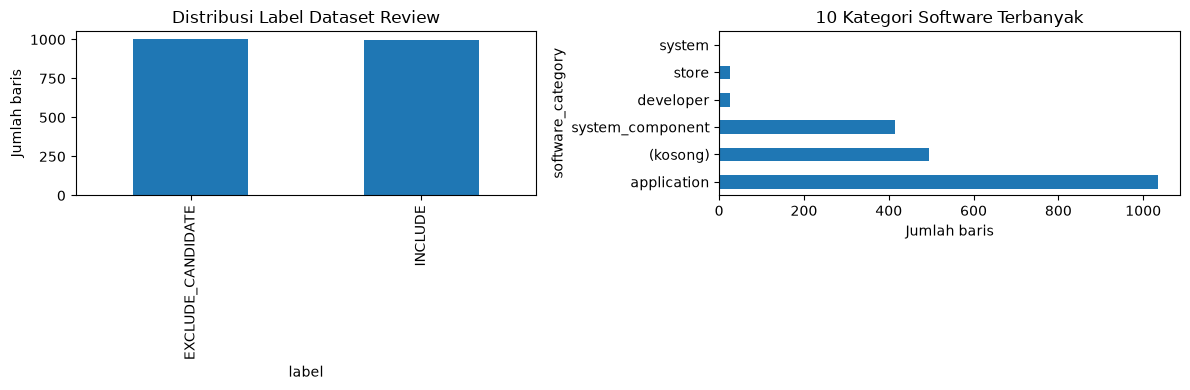

In [ ]:
label_counts = original_labeled['label'].astype('string').str.strip().str.upper().value_counts()
category_counts = original_labeled['software_category'].fillna('(empty)').astype(str).value_counts()
display(label_counts.to_frame('count'))
display(category_counts.head(15).to_frame('count'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
label_counts.plot(kind='bar', ax=axes[0], title='Distribusi Label Dataset Review')
category_counts.head(10).plot(kind='barh', ax=axes[1], title='10 Kategori Software Terbanyak')
axes[0].set_ylabel('Jumlah baris')
axes[1].set_xlabel('Jumlah baris')
plt.tight_layout()
fig.savefig(FIG_DIR / '01_label_dan_kategori.png', dpi=170, bbox_inches='tight')
plt.show()

#### KODE 07 — Tabulasi kategori versus label

In [8]:
cross_tab = pd.crosstab(
    original_labeled['software_category'].fillna('(kosong)'),
    original_labeled['label'].astype('string').str.strip().str.upper(),
    margins=True
)
display(cross_tab)
cross_tab.to_csv(OUT_DIR / '02_crosstab_kategori_label.csv')
print('Catatan: software_category hanya dipakai sebagai deskripsi; bukan fitur ML utama.')

label,EXCLUDE_CANDIDATE,INCLUDE,All
software_category,,,
(kosong),268,228,496
application,285,750,1035
developer,19,7,26
store,12,13,25
system,3,0,3
system_component,415,0,415
All,1002,998,2000


Catatan: software_category hanya dipakai sebagai deskripsi; bukan fitur ML utama.


#### KODE 08 — Audit perulangan nama dan label sebelum modeling

In [9]:
name_key = clean_key(original_labeled['software_name'])
label_key = original_labeled['label'].astype('string').str.strip().str.upper()
print('Nama software kosong:', int((name_key == '').sum()))
print('Nama duplikat setelah normalisasi sederhana:', int(name_key.duplicated().sum()))
conflicts = (pd.DataFrame({'name_key': name_key, 'label_key': label_key})
             .query("name_key != ''").groupby('name_key')['label_key']
             .nunique(dropna=True))
print('Nama dengan label berbeda:', int((conflicts > 1).sum()))

Nama software kosong: 0
Nama duplikat setelah normalisasi sederhana: 0
Nama dengan label berbeda: 0


## 4.3 Data Preparation

**Tujuan:** menyiapkan teks untuk TF-IDF, menguji validitas label, membuang nama kosong serta duplikasi identik, memisahkan keluarga nama agar varian sangat mirip tidak otomatis tersebar pada training dan testing. Nama asli disimpan di tabel hasil; preprocessing hanya digunakan pada fitur model.

#### KODE 09 — Normalisasi label dan nama software (tanpa mengubah data sumber)

In [10]:
def normalize_name(value):
    if pd.isna(value):
        return ''
    s = str(value).casefold()
    s = s.replace('®', ' ').replace('™', ' ')
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def normalize_label(value):
    if pd.isna(value):
        return ''
    s = str(value).strip().upper().replace(' ', '_').replace('-', '_')
    return {'EXCLUDE': 'EXCLUDE_CANDIDATE', 'EXCLUDECANDIDATE': 'EXCLUDE_CANDIDATE'}.get(s, s)

data = original_labeled.copy()
data['name_clean'] = data['software_name'].map(normalize_name)
data['label_final'] = data['label'].map(normalize_label)
print('Label normalized:')
print(data['label_final'].value_counts(dropna=False).to_string())

Label normalized:
label_final
EXCLUDE_CANDIDATE    1002
INCLUDE               998


#### KODE 10 — Memisahkan data yang belum siap dilatih

In [11]:
usable = data[(data['name_clean'] != '') & (data['label_final'].isin(VALID_LABELS))].copy()
review_needed = data[~data.index.isin(usable.index)].copy()
print('Siap untuk modeling:', len(usable))
print('Belum siap:', len(review_needed))
review_needed.to_csv(OUT_DIR / '03_label_perlu_review.csv', index=False, encoding='utf-8-sig')
if usable['label_final'].nunique() < 2:
    raise ValueError('Pelatihan membutuhkan setidaknya dua kelas INCLUDE dan EXCLUDE_CANDIDATE.')

Siap untuk modeling: 2000
Belum siap: 0


#### KODE 11 — Mendeteksi konflik dan menghapus duplikasi nama identik

In [12]:
conflict_names = (usable.groupby('name_clean')['label_final'].nunique()
                  .loc[lambda v: v > 1].index)
conflict_rows = usable[usable['name_clean'].isin(conflict_names)]
conflict_rows.to_csv(OUT_DIR / '04_konflik_label.csv', index=False, encoding='utf-8-sig')
if len(conflict_rows):
    print('Konflik label ditemukan:', len(conflict_names), 'nama. Baris konflik dikeluarkan dari model.')
    usable = usable[~usable['name_clean'].isin(conflict_names)]
else:
    print('Tidak ada konflik label pada nama yang identik.')

before_dedup = len(usable)
usable = usable.drop_duplicates(subset=['name_clean'], keep='first').reset_index(drop=True)
print('Duplikasi identik dihapus:', before_dedup - len(usable))
print('Dataset akhir berlabel:', usable.shape)
usable.to_csv(OUT_DIR / '05_data_bersih_berlabel.csv', index=False, encoding='utf-8-sig')

Tidak ada konflik label pada nama yang identik.
Duplikasi identik dihapus: 0
Dataset akhir berlabel: (2000, 8)


#### KODE 12 — Membuat kunci keluarga software untuk audit kebocoran data

In [13]:
def approximate_family(name):
    # Heuristic grouping only, NOT a verified software-product ontology.
    text = normalize_name(name)
    tokens = re.findall(r'[a-z]+', text)
    stop = {'version', 'v', 'x', 'x86', 'x64', 'bit', 'bits', 'for', 'and', 'the',
            'en', 'us', 'id', 'in', 'on', 'of', 'edition', 'build'}
    words = [t for t in tokens if t not in stop and len(t) > 1]
    return ' '.join(words[:3]) if words else 'special-' + text[:25]

usable['family_group'] = usable['name_clean'].map(approximate_family)
print('Jumlah kelompok heuristik:', usable['family_group'].nunique())
print('Kelompok besar (perlu diperiksa apakah benar satu keluarga):')
display(usable['family_group'].value_counts().head(15).to_frame('count'))
usable[['software_name', 'family_group', 'label_final']].to_csv(
    OUT_DIR / '06_audit_family_groups.csv', index=False, encoding='utf-8-sig'
)

Jumlah kelompok heuristik: 899
Kelompok besar (perlu diperiksa apakah benar satu keluarga):


,count
family_group,
coreldraw graphics suite,107
siemens totally integrated,95
ultraviewer,39
microsoft visual studio,30
autodesk navisworks freedom,27
autodesk material library,23
catalyst control center,22
microsoft sql server,20
zip,20


#### KODE 13 — Memisahkan training dan testing berdasarkan keluarga software

In [14]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split

X = usable['name_clean']
y = usable['label_final']
groups = usable['family_group']

# Stronger than a random row split because similar version names often share families.
cv_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(cv_outer.split(X, y, groups))
train_df = usable.iloc[train_idx].copy().reset_index(drop=True)
test_df = usable.iloc[test_idx].copy().reset_index(drop=True)
assert set(train_df.family_group).isdisjoint(set(test_df.family_group))
if train_df.label_final.nunique() < 2 or test_df.label_final.nunique() < 2:
    raise ValueError('Kelas dalam train/test tidak lengkap. Periksa distribusi kelompok.')
print('Train:', len(train_df), 'Test:', len(test_df))
print('Train labels:', train_df.label_final.value_counts().to_dict())
print('Test labels:', test_df.label_final.value_counts().to_dict())
train_df.to_csv(OUT_DIR / '07_train_set.csv', index=False, encoding='utf-8-sig')
test_df.to_csv(OUT_DIR / '08_test_set.csv', index=False, encoding='utf-8-sig')

Train: 1600 Test: 400
Train labels: {'EXCLUDE_CANDIDATE': 802, 'INCLUDE': 798}
Test labels: {'EXCLUDE_CANDIDATE': 200, 'INCLUDE': 200}


## 4.4 Modeling

**Input model:** nama software yang dinormalisasi. `software_category` dan label usulan otomatis tidak dijadikan fitur prediktor, untuk menghindari ketergantungan pada kategori sistem yang belum tentu konsisten.

**Dua model pembanding:** TF-IDF character n-gram + Logistic Regression dan TF-IDF character n-gram + Linear SVM. TF-IDF ditempatkan **di dalam Pipeline** dan baru dipelajari pada training set (mencegah kebocoran IDF dari testing set). Pemilihan model memakai cross-validation pada training, sedangkan testing digunakan hanya untuk evaluasi final.

#### KODE 14 — Definisi preprocessing TF-IDF dan dua model

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

def build_vectorizer():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                           min_df=2, max_features=60000, sublinear_tf=True)
models = {
    'Logistic Regression': Pipeline([
        ('tfidf', build_vectorizer()),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced',
                                     random_state=RANDOM_STATE))
    ]),
    'Linear SVM': Pipeline([
        ('tfidf', build_vectorizer()),
        ('model', LinearSVC(class_weight='balanced', random_state=RANDOM_STATE,
                            max_iter=10000))
    ])
}
print('Models:', list(models))

Models: ['Logistic Regression', 'Linear SVM']


#### KODE 15 — Cross-validation pada training set (tanpa menyentuh testing)

In [16]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score

train_group_n = train_df['family_group'].nunique()
n_splits = min(3, int(train_group_n))
if n_splits < 2:
    raise ValueError('Terlalu sedikit family groups untuk cross-validation.')
cv_inner = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE + 1)
cv_results = []
for model_name, pipeline in models.items():
    scores = cross_validate(pipeline, train_df['name_clean'], train_df['label_final'],
                            groups=train_df['family_group'], cv=cv_inner,
                            scoring='f1_macro', n_jobs=1, error_score='raise')
    cv_results.append({'model': model_name,
                       'cv_f1_macro_mean': scores['test_score'].mean(),
                       'cv_f1_macro_std': scores['test_score'].std(),
                       'cv_folds': n_splits})
cv_table = pd.DataFrame(cv_results).sort_values('cv_f1_macro_mean', ascending=False)
display(cv_table)
cv_table.to_csv(OUT_DIR / '09_cross_validation.csv', index=False)
best_model_name = str(cv_table.iloc[0]['model'])
print('Model dipilih menggunakan training-CV:', best_model_name)

,model,cv_f1_macro_mean,cv_f1_macro_std,cv_folds
1,Linear SVM,0.923981,0.028514,3
0,Logistic Regression,0.903478,0.024572,3


Model dipilih menggunakan training-CV: Linear SVM


#### KODE 16 — Pelatihan Logistic Regression dan Linear SVM

In [17]:
from sklearn.base import clone
fitted_models = {}
for model_name, pipeline in models.items():
    model = clone(pipeline)
    model.fit(train_df['name_clean'], train_df['label_final'])
    fitted_models[model_name] = model
    print('Training selesai:', model_name)

Training selesai: Logistic Regression
Training selesai: Linear SVM


## 4.5 Evaluation

**Metrik:** Accuracy, Macro Precision, Macro Recall, Macro F1, F1 kelas EXCLUDE_CANDIDATE, dan confusion matrix. Macro F1 penting untuk menjaga kedua kelas tetap diperhitungkan. Untuk deployment, kesalahan mengeluarkan aplikasi utama (**false EXCLUDE**) perlu diperhatikan secara khusus.

#### KODE 17 — Menghitung metrik kedua model di testing set

In [18]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix

LABEL_ORDER = ['INCLUDE', 'EXCLUDE_CANDIDATE']
true_y = test_df['label_final']
predictions = {}
metrics_rows = []
for model_name, model in fitted_models.items():
    pred = model.predict(test_df['name_clean'])
    predictions[model_name] = pred
    prec, rec, f1, _ = precision_recall_fscore_support(true_y, pred,
        labels=LABEL_ORDER, zero_division=0)
    cm = confusion_matrix(true_y, pred, labels=LABEL_ORDER)
    metrics_rows.append({
        'model': model_name,
        'test_count': len(test_df),
        'accuracy': accuracy_score(true_y, pred),
        'macro_precision': prec.mean(),
        'macro_recall': rec.mean(),
        'macro_f1': f1.mean(),
        'exclude_precision': prec[1],
        'exclude_recall': rec[1],
        'exclude_f1': f1[1],
        'false_exclude_main_apps': int(cm[0, 1]),
        'missed_exclude_candidates': int(cm[1, 0])
    })
metrics_table = pd.DataFrame(metrics_rows).sort_values('model')
display(metrics_table)
metrics_table.to_csv(OUT_DIR / '10_test_metrics.csv', index=False)
for model_name, pred in predictions.items():
    print('\n==', model_name, '==')
    print(classification_report(true_y, pred, zero_division=0))

,model,test_count,accuracy,macro_precision,macro_recall,macro_f1,exclude_precision,exclude_recall,exclude_f1,false_exclude_main_apps,missed_exclude_candidates
1,Linear SVM,400,0.970,0.970188,0.970,0.969997,0.960784,0.98,0.970297,8,4
0,Logistic Regression,400,0.945,0.947191,0.945,0.944933,0.915888,0.98,0.946860,18,4



== Logistic Regression ==
                   precision    recall  f1-score   support

EXCLUDE_CANDIDATE       0.92      0.98      0.95       200
          INCLUDE       0.98      0.91      0.94       200

         accuracy                           0.94       400
        macro avg       0.95      0.95      0.94       400
     weighted avg       0.95      0.94      0.94       400


== Linear SVM ==
                   precision    recall  f1-score   support

EXCLUDE_CANDIDATE       0.96      0.98      0.97       200
          INCLUDE       0.98      0.96      0.97       200

         accuracy                           0.97       400
        macro avg       0.97      0.97      0.97       400
     weighted avg       0.97      0.97      0.97       400



#### KODE 18 — Confusion matrix kedua model

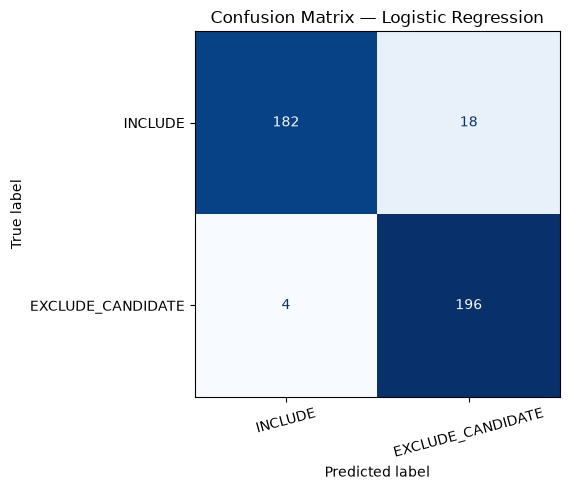

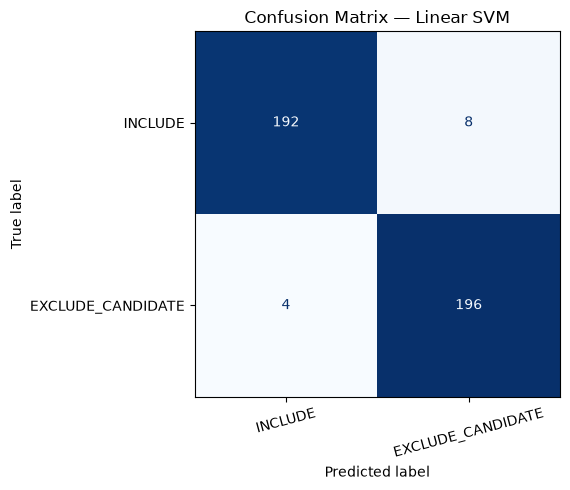

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
for model_name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(true_y, pred, labels=LABEL_ORDER,
        display_labels=LABEL_ORDER, cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'Confusion Matrix — {model_name}')
    plt.xticks(rotation=15)
    plt.tight_layout()
    fig.savefig(FIG_DIR / ('02_confusion_' + model_name.lower().replace(' ', '_') + '.png'),
                dpi=170, bbox_inches='tight')
    plt.show()

#### KODE 19 — Analisis salah klasifikasi

In [20]:
errors = []
for model_name, pred in predictions.items():
    temp = test_df[['software_id', 'software_name', 'manufacturer',
                     'software_category', 'label_final']].copy()
    temp['model'] = model_name
    temp['predicted_label'] = pred
    temp['error_type'] = np.where(temp['label_final'] == temp['predicted_label'],
                                  'CORRECT', 'MISCLASSIFIED')
    errors.append(temp)
error_table = pd.concat(errors, ignore_index=True)
misclassified = error_table[error_table.error_type == 'MISCLASSIFIED']
print('Jumlah kesalahan masing-masing model:')
display(misclassified.groupby('model').size().to_frame('mistakes'))
display(misclassified.head(20))
error_table.to_csv(OUT_DIR / '11_all_test_predictions.csv', index=False, encoding='utf-8-sig')
misclassified.to_csv(OUT_DIR / '12_misclassified_review.csv', index=False, encoding='utf-8-sig')

Jumlah kesalahan masing-masing model:


,mistakes
model,
Linear SVM,12
Logistic Regression,22


,software_id,software_name,manufacturer,software_category,label_final,model,predicted_label,error_type
9,"21,422",Siemens Totally Integrated Automation Portal V15,Siemens AG,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
45,"29,056",DaVinci Resolve Control Panels,Blackmagic Design,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
90,"17,408",SAP GUI for Windows 7.30,SAP,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
102,"6,272",Autodesk AutoCAD 2017 Hotfix 2,AUTODESK,NaN,EXCLUDE_CANDIDATE,Logistic Regression,INCLUDE,MISCLASSIFIED
103,"6,273",Autodesk AutoCAD 2017 Hotfix 3,AUTODESK,NaN,EXCLUDE_CANDIDATE,Logistic Regression,INCLUDE,MISCLASSIFIED
111,"21,256",Handset WinDriver 1.02.03.00,"Huawei technologies Co., Ltd.",application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
113,"24,108",PuTTY release 0.83 (64-bit),Simon Tatham,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
120,"26,118",SAP GUI for Windows 7.40,SAP,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
122,"23,698",IObit Uninstaller 14.2.0.2,IObit,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED
146,"26,549",PuTTY release 0.76 (64-bit),Simon Tatham,application,INCLUDE,Logistic Regression,EXCLUDE_CANDIDATE,MISCLASSIFIED


#### KODE 20 — Baseline sederhana sebagai pembanding (BUKAN rule GLPI)

In [21]:
def keyword_baseline(name):
    # Transparent heuristic, not a faithful emulator of GLPI Software Dictionary.
    rule = r'language pack|redistributable|\bpatch\b|\bupdate\b|\bdriver\b|runtime|\bhotfix\b|\bmui\b|setup package|setuppackage'
    return 'EXCLUDE_CANDIDATE' if re.search(rule, name, flags=re.I) else 'INCLUDE'

baseline_pred = test_df['name_clean'].map(keyword_baseline)
base_precision, base_recall, base_f1, _ = precision_recall_fscore_support(
    true_y, baseline_pred, labels=LABEL_ORDER, zero_division=0
)
baseline_results = pd.DataFrame([{
    'model': 'Keyword Baseline (NOT GLPI Rules)',
    'test_count': len(test_df),
    'accuracy': accuracy_score(true_y, baseline_pred),
    'macro_precision': base_precision.mean(),
    'macro_recall': base_recall.mean(),
    'macro_f1': base_f1.mean(),
    'exclude_precision': base_precision[1],
    'exclude_recall': base_recall[1],
    'exclude_f1': base_f1[1]
}])
display(pd.concat([baseline_results, metrics_table], ignore_index=True)[
    ['model', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'exclude_recall']])
baseline_results.to_csv(OUT_DIR / '13_keyword_baseline.csv', index=False)

,model,accuracy,macro_precision,macro_recall,macro_f1,exclude_recall
0,Keyword Baseline (NOT GLPI Rules),0.885,0.906504,0.885,0.883459,0.77
1,Linear SVM,0.970,0.970188,0.970,0.969997,0.98
2,Logistic Regression,0.945,0.947191,0.945,0.944933,0.98


#### KODE 21 — Analisis awal aturan Dictionary (opsional; tidak disamakan dengan kelas)

In [23]:
rule_path = BASE_DIR / 'Rule_Software_Dictionary.csv'
if rule_path.exists():
    rule_data = pd.read_csv(rule_path)
    print('Rule tersedia:', len(rule_data))
    display(rule_data['action'].value_counts(dropna=False).to_frame('count'))
    display(rule_data['operator'].value_counts(dropna=False).to_frame('count'))
    print('Catatan: tindakan Ignore import bukan definisi otomatis EXCLUDE_CANDIDATE.')
    print('Audit ini tidak menguji urutan prioritas dan kondisi lengkap engine GLPI.')
else:
    print('File audit Dictionary tidak tersedia. Tidak memengaruhi modeling.')

Rule tersedia: 67


,count
action,
Ignore import,65
Software Assign,1
Unspecified,1


,count
operator,
contains,47
is,10
starting with,8
regular expression matches,1
unknown,1


Catatan: tindakan Ignore import bukan definisi otomatis EXCLUDE_CANDIDATE.
Audit ini tidak menguji urutan prioritas dan kondisi lengkap engine GLPI.


#### KODE 22 — Ringkasan dan pemilihan model berdasarkan CV

In [24]:
selected_test_row = metrics_table.loc[metrics_table.model == best_model_name].iloc[0]
summary = {
    'source_dataset': str(source_path.name),
    'source_label_note': 'Pastikan isi file adalah label final hasil review Pak Widi',
    'raw_rows': None if raw_data is None else int(len(raw_data)),
    'labeled_raw_rows': int(len(original_labeled)),
    'labeled_used_rows': int(len(usable)),
    'train_rows': int(len(train_df)),
    'test_rows': int(len(test_df)),
    'group_overlap': bool(set(train_df.family_group) & set(test_df.family_group)),
    'best_model_by_cv': best_model_name,
    'selected_model_test_accuracy': float(selected_test_row['accuracy']),
    'selected_model_test_macro_f1': float(selected_test_row['macro_f1']),
    'selected_model_false_excludes': int(selected_test_row['false_exclude_main_apps']),
    'selected_model_missed_excludes': int(selected_test_row['missed_exclude_candidates']),
}
(OUT_DIR / '14_experiment_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2))

{
  "source_dataset": "Software_GLPI_2000.xlsx",
  "source_label_note": "Pastikan isi file adalah label final hasil review Pak Widi",
  "raw_rows": 12318,
  "labeled_raw_rows": 2000,
  "labeled_used_rows": 2000,
  "train_rows": 1600,
  "test_rows": 400,
  "group_overlap": false,
  "best_model_by_cv": "Linear SVM",
  "selected_model_test_accuracy": 0.97,
  "selected_model_test_macro_f1": 0.96999699969997,
  "selected_model_false_excludes": 8,
  "selected_model_missed_excludes": 4
}


## 4.6 Deployment (Prototipe Pendukung Keputusan)

**Deployment tidak mengubah GLPI.** Setelah model dipilih dan dievaluasi pada test holdout, latih kembali model terpilih dengan seluruh **data berlabel yang valid**, simpan pipeline (TF-IDF + model), dan jalankan prediksi untuk data software baru. Jika diperlukan, hasilnya diekspor dalam Excel untuk review tim IT.

**Hindari otomatisasi penghapusan:** `EXCLUDE_CANDIDATE` hanyalah tanda untuk review, bukan perintah menghapus data atau menonaktifkan import. Model hanya menerima *software_name*; tidak menentukan lisensi, keamanan, atau hak akses.

#### KODE 23 — Membuat model final untuk deployment

In [25]:
import joblib
final_model = clone(models[best_model_name])
final_model.fit(usable['name_clean'], usable['label_final'])
model_path = MODEL_DIR / 'software_classifier_final.joblib'
joblib.dump(final_model, model_path)
metadata = {
    'input_feature': 'software_name',
    'classes': list(final_model.classes_),
    'model': best_model_name,
    'training_rows': int(len(usable)),
    'note': 'For IT review only; no automatic GLPI database changes'
}
(MODEL_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Model disimpan:', model_path)

Model disimpan: c:\Users\magang.tiga\Documents\CODE_GLPI\output_bab4\models\software_classifier_final.joblib


#### KODE 24 — Fungsi prediksi untuk nama software baru

In [26]:
def predict_software(software_names, model=final_model):
    original_names = pd.Series(software_names, dtype='string').fillna('')
    cleaned = original_names.map(normalize_name)
    valid = cleaned.ne('')
    predictions = np.full(len(cleaned), 'REVIEW', dtype=object)
    if valid.any():
        predictions[valid.to_numpy()] = model.predict(cleaned[valid])
    result = pd.DataFrame({'software_name': original_names, 'predicted_label': predictions})
    result['status'] = np.where(result['predicted_label'] == 'REVIEW',
                                'CHECK_NAME', 'IT_REVIEW_REQUIRED')
    return result

example = predict_software([
    'Microsoft Office Home and Business 2021',
    'AutoCAD 2025 Language Pack - English',
    'Microsoft Visual C++ 2015-2022 Redistributable',
    ''
])
display(example)

,software_name,predicted_label,status
0,Microsoft Office Home and Business 2021,INCLUDE,IT_REVIEW_REQUIRED
1,AutoCAD 2025 Language Pack - English,EXCLUDE_CANDIDATE,IT_REVIEW_REQUIRED
2,Microsoft Visual C++ 2015-2022 Redistributable,EXCLUDE_CANDIDATE,IT_REVIEW_REQUIRED
3,,REVIEW,CHECK_NAME


#### KODE 25 — Prediksi dataset mentah seluruhnya jika tersedia

In [ ]:
if raw_data is not None:
    deployed = raw_data.copy()
    predicted = predict_software(deployed['software_name'])
    deployed['predicted_label'] = predicted['predicted_label'].to_numpy()
    deployed['status'] = predicted['status'].to_numpy()
    print('Total prediksi data mentah:', len(deployed))
    print(deployed['predicted_label'].value_counts(dropna=False).to_string())
    deployed.to_csv(OUT_DIR / '15_prediksi_software_mentah.csv',
                    index=False, encoding='utf-8-sig')
else:
    deployed = usable[['software_id', 'software_name', 'manufacturer',
                       'software_category', 'entity_id']].copy()
    predicted = predict_software(deployed['software_name'])
    deployed['predicted_label'] = predicted['predicted_label'].to_numpy()
    deployed['status'] = predicted['status'].to_numpy()
    deployed.to_csv(OUT_DIR / '15_prediksi_software_mentah.csv',
                    index=False, encoding='utf-8-sig')
    print('Data mentah tidak tersedia; prototipe menunjukkan prediksi pada data berlabel.')

#### KODE 26 — Ekspor workbook untuk review IT

In [ ]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

cols = ['software_id', 'software_name', 'manufacturer',
        'software_category', 'entity_id', 'predicted_label', 'status']
export_rows = deployed.reindex(columns=cols).fillna('')
wb = Workbook()
ws = wb.active
ws.title = 'Prediksi Review IT'
ws.append(cols)
for values in export_rows.itertuples(index=False, name=None):
    ws.append([str(v) if v != '' else '' for v in values])
ws.freeze_panes = 'C2'
ws.auto_filter.ref = f'A1:G{ws.max_row}'
for cell in ws[1]:
    cell.font = Font(bold=True, color='FFFFFF')
    cell.fill = PatternFill('solid', fgColor='17324D')
    cell.alignment = Alignment(wrap_text=True)
for col, width in {'A':15, 'B':68, 'C':32, 'D':22, 'E':14,
                   'F':24, 'G':22}.items():
    ws.column_dimensions[col].width = width
ws.sheet_view.showGridLines = False
for row in ws.iter_rows(min_row=2):
    for c in row[:5]: c.font = Font(color='00804A')
    row[5].font = Font(color='C66A00')
output_excel = OUT_DIR / '16_rekomendasi_klasifikasi_review_IT.xlsx'
wb.save(output_excel)
print('Workbook siap:', output_excel)

#### KODE 27 — Membuat rekap artefak eksperimen

In [ ]:
print('HASIL ANALISIS BAB IV')
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file():
        print(f'{p.relative_to(OUT_DIR)} — {p.stat().st_size / 1024:.1f} KB')
print('\nPENTING: Angka performa hanya sah disebut evaluasi berlabel IT jika input benar-benar file hasil review Pak Widi.')

## 4.7 Panduan Penulisan Pembahasan

1. **4.1 Business Understanding** — Uraikan masalah operasional dan keputusan apa yang ingin dibantu oleh model. Hindari klaim bahwa Dictionary tidak mendukung regex atau bahwa GLPI pasti menjadi lambat akibat banyaknya entri.
2. **4.2 Data Understanding** — Gunakan tabel dan diagram dari KODE 03–08. Jelaskan 12.318 baris mentah berbeda dari 2.000 sampel berlabel, serta kemungkinan bias sampel 1.000:1.000.
3. **4.3 Data Preparation** — Tulis aturan normalisasi, perlakuan nama kosong, konflik label, deduplikasi, dan strategi split berbasis kelompok. Family grouping berbasis heuristik; bukan master data produk resmi.
4. **4.4 Modeling** — Jelaskan TF-IDF character 2–5 gram dan alasan Logistic Regression / Linear SVM cocok untuk teks nama software yang pendek dan bervariasi. Semua TF-IDF fit dilakukan di data train.
5. **4.5 Evaluation** — Gunakan `10_test_metrics.csv`, gambar confusion matrix, `12_misclassified_review.csv`, serta baseline heuristik yang **bukan** simulasi Dictionary GLPI. Diskusikan kesalahan `INCLUDE → EXCLUDE_CANDIDATE` sebagai risiko utama.
6. **4.6 Deployment** — Tunjukkan file model joblib, fungsi prediksi dan workbook hasil rekomendasi. Tidak ada perubahan database GLPI atau aturan produksi.

**Batasan:** label hanya merepresentasikan keputusan domain expert dan kriteria lokal; tidak memvalidasi legalitas aplikasi. Kinerja pada 2.000 sampel terpilih tidak otomatis merepresentasikan seluruh populasi GLPI. Untuk mengklaim perbaikan terhadap GLPI Dictionary secara langsung, perlu evaluasi *baseline* yang benar-benar mereplikasi operator, urutan, dan aksi rule yang berlaku.